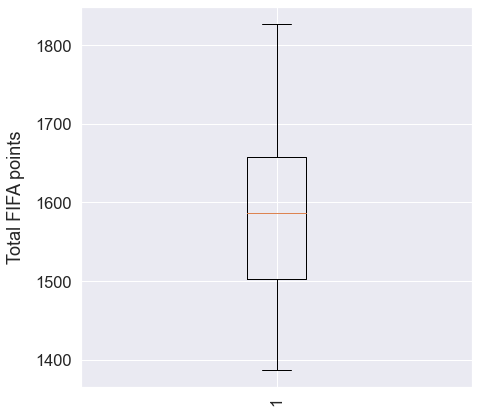

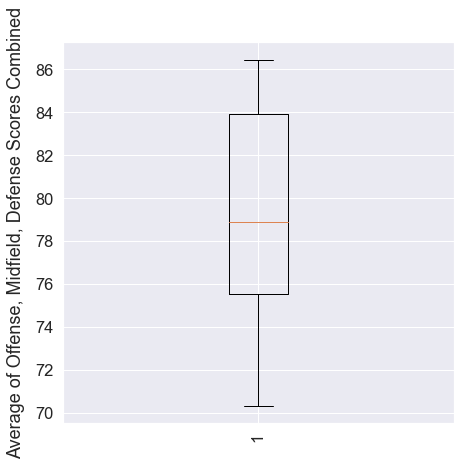

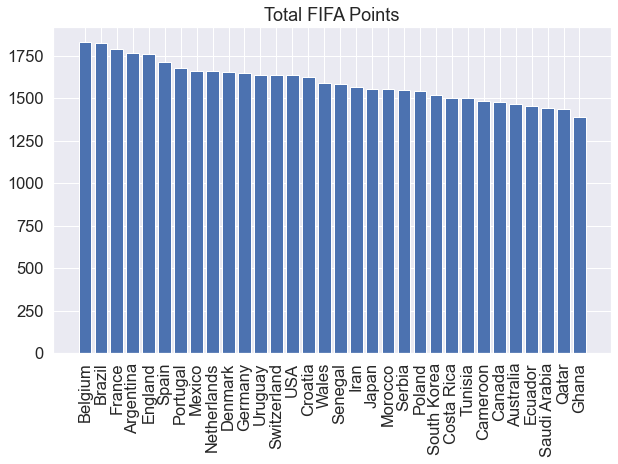

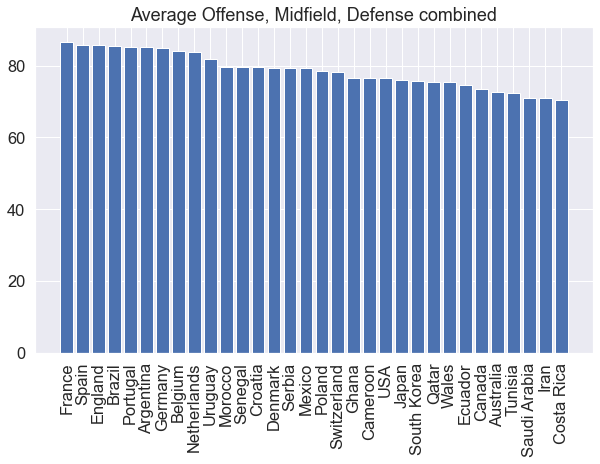

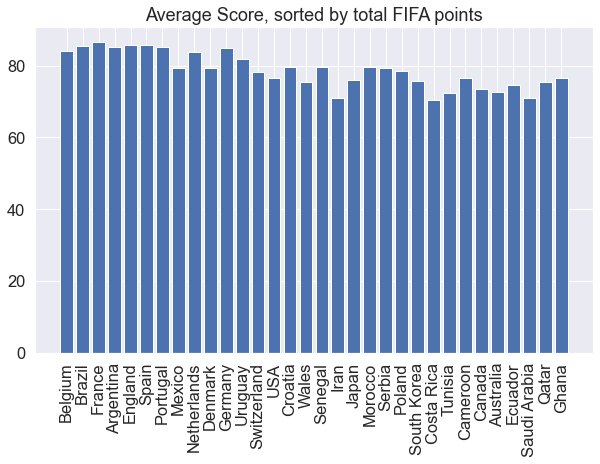

In [27]:
#data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("international_matches.csv")
df = df.replace({"IR Iran": "Iran", "Korea Republic" : "South Korea"}) # normalize country names
df = df.fillna(df.mean()) # fill nan with mean

df = df[df['date'] > '2018-06-14'] # include international matches starting from world cup 2018

#countries that are in the worldcup
countries = ['Netherlands', 'Senegal', 'Ecuador', 'Qatar', 
            'England', 'USA', 'Iran', 'Wales', 
            'Poland', 'Argentina', 'Saudi Arabia', 'Mexico', 
            'France', 'Australia', 'Denmark', 'Tunisia', 
            'Spain' , 'Japan', 'Costa Rica', 'Germany', 
            'Croatia', 'Morocco', 'Belgium' , 'Canada',
            'Brazil', 'Switzerland', 'Cameroon', 'Serbia', 
            'Portugal', 'Ghana', 'South Korea', 'Uruguay']

#select only datas that are in the world cup
df = df[df['home_team'].isin(countries)]

# create new columns and adding features
df['point_difference'] = df['home_team_total_fifa_points'] - df['away_team_total_fifa_points'] 
df['score_difference'] = df['home_team_score'] - df['away_team_score']
df['offense_difference'] = df['home_team_mean_offense_score'] - df['away_team_mean_offense_score']
df['midfield_difference'] = df['home_team_mean_midfield_score'] - df['away_team_mean_midfield_score']
df['defense_difference'] = df['home_team_mean_defense_score'] - df['away_team_mean_defense_score']
df['average_score'] = (df['home_team_mean_offense_score'] + df['home_team_mean_midfield_score'] + df['home_team_mean_defense_score']) / 3
df['rank_difference'] = df['home_team_fifa_rank'] - df['away_team_fifa_rank']
df['is_won'] = df['score_difference'] > 0 

most_recent_df = pd.DataFrame()

for country in countries:
    temp_df = df.sort_values(by=['date'], ascending=False)
    most_recent_df = most_recent_df.append(temp_df[temp_df['home_team'] == country].iloc[0])

plt.figure(figsize=(7,7))
plt.boxplot(np.array(most_recent_df['home_team_total_fifa_points']))
plt.xticks(rotation=90)
plt.ylabel('Total FIFA points', labelpad=10)
plt.show()

plt.figure(figsize=(7,7))
plt.boxplot(np.array(most_recent_df['average_score']))
plt.xticks(rotation=90)
plt.ylabel('Average of Offense, Midfield, Defense Scores Combined', labelpad=10)
plt.show()

plt.figure(figsize=(10,6))
temp_df = most_recent_df.sort_values('home_team_total_fifa_points', ascending=False)
plt.title('Total FIFA Points')
plt.bar(temp_df['home_team'].to_list(), temp_df['home_team_total_fifa_points'])
plt.xticks(rotation=90)
plt.show()

plt.figure(figsize=(10,6))
temp_df = most_recent_df.sort_values('average_score', ascending=False)
plt.title('Average Offense, Midfield, Defense combined')
plt.bar(temp_df['home_team'].to_list(), temp_df['average_score'])
plt.xticks(rotation=90)
plt.show()

plt.figure(figsize=(10,6))
temp_df = most_recent_df.sort_values('home_team_total_fifa_points', ascending=False)
plt.title('Average Score, sorted by total FIFA points')
plt.bar(temp_df['home_team'].to_list(), temp_df['average_score'])
plt.xticks(rotation=90)
plt.show()

0.6811797752808989
0.6952247191011236


Text(61.5, 0.5, '# of Neurons')

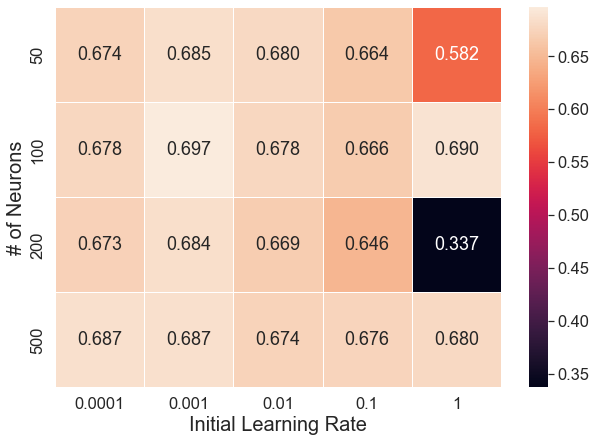

In [28]:
model_accuracy_score = []
models = []

X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference']], df['is_won']
X = np.asmatrix(X)
y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#support vector machine
svc = SVC(probability=True)
svc.fit(X_train, y_train)
y_predict = svc.predict(X_train)
print(accuracy_score(y_train, y_predict))

model_accuracy_score.append(accuracy_score(y_train, y_predict))
models.append("Support Vector Machine")

#logistic Regression
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_predict = logreg.predict(X_train)
print(accuracy_score(y_train, y_predict))

model_accuracy_score.append(accuracy_score(y_train, y_predict))
models.append("Logistic Regression")

#Multi-layer perceptron
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import seaborn as sns

splits = KFold(n_splits=3)
hidden_layers = [50, 100, 200, 500]
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1]
scores = [] # 2d array to store accuracy scores of the parameter combinations

for layer in hidden_layers:
    score = []

    for rate in learning_rates:
        total = 0

        for train_index, val_index in splits.split(X_train):
            mlp = MLPClassifier(hidden_layer_sizes=layer, activation='tanh', solver='sgd', learning_rate_init=rate)
            X_subtrain = X_train[train_index]
            X_val = X_train[val_index]
            y_subtrain = y_train[train_index]
            y_val = y_train[val_index]
            
            mlp.fit(X_subtrain, y_subtrain)
            y_predict = mlp.predict(X_val)
            total += accuracy_score(y_val, y_predict)

        score.append(total/3) # append the average score
    scores.append(score)

plt.figure(figsize=(10,7)) # create heatmap
sns.set(font_scale=1.5)
ht = sns.heatmap(scores, annot=True, linewidths=.5, xticklabels=[str(rate) for rate in learning_rates], yticklabels=[str(layer) for layer in hidden_layers], fmt='.3f')
ht.set_xlabel("Initial Learning Rate", fontsize=20)
ht.set_ylabel("# of Neurons", fontsize=20)



In [29]:
#make group stage into 8 groups of 4 countries
wc_df = pd.DataFrame({'country': countries,
                    'group': ['A', 'A', 'A', 'A', 
                            'B', 'B', 'B', 'B',
                            'C', 'C', 'C', 'C',
                            'D', 'D', 'D', 'D',
                            'E', 'E', 'E', 'E', 
                            'F', 'F', 'F', 'F', 
                            'G', 'G', 'G', 'G',
                            'H', 'H', 'H', 'H']})
wc_df['expected_points'] = 0

country_win_prob = {country: list() for country in wc_df['country'].to_list()}
country_exp_points = {country: 0 for country in wc_df['country'].to_list()}

0.7148876404494382


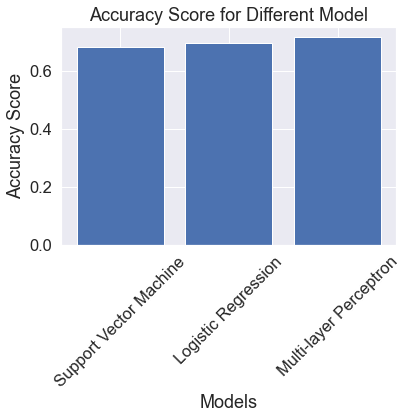

In [30]:
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference']], df['is_won']
X = np.asmatrix(X)
y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
mlp = MLPClassifier(hidden_layer_sizes=50, activation='tanh', solver='sgd', learning_rate_init=0.001)
mlp.fit(X_train, y_train)
y_predict = mlp.predict(X_train)
print(accuracy_score(y_train, y_predict))
model_accuracy_score.append(accuracy_score(y_train, y_predict))
models.append("Multi-layer Perceptron")

#plot the accuracy score of different models
plt.bar(models, model_accuracy_score)
plt.title("Accuracy Score for Different Model")
plt.xlabel("Models")
plt.ylabel("Accuracy Score")
plt.xticks(rotation=45)
plt.show()

0.699438202247191
0.7219101123595506
0.7247191011235955


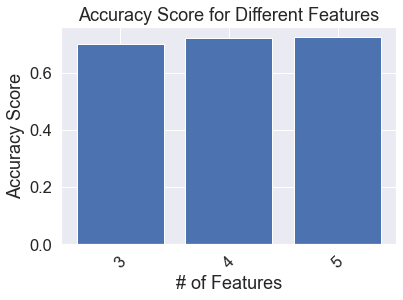

In [31]:
feature_accuracy = []
number_of_features = []

#Accuracy score of 3 features
X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference']], df['is_won']
X = np.asmatrix(X)
y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
mlp = MLPClassifier(hidden_layer_sizes=50, activation='tanh', solver='sgd', learning_rate_init=0.001)
mlp.fit(X_train, y_train)
y_predict = mlp.predict(X_train)
print(accuracy_score(y_train, y_predict))
feature_accuracy.append(accuracy_score(y_train, y_predict))
number_of_features.append("3")

#Accuracy score of 4 features
X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference', 'rank_difference']], df['is_won']
X = np.asmatrix(X)
y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
mlp1 = MLPClassifier(hidden_layer_sizes=50, activation='tanh', solver='sgd', learning_rate_init=0.001)
mlp1.fit(X_train, y_train)
y_predict = mlp1.predict(X_train)
print(accuracy_score(y_train, y_predict))
feature_accuracy.append(accuracy_score(y_train, y_predict))
number_of_features.append("4")

#Accuracy score of 5 features
X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference', 'rank_difference', 'point_difference']], df['is_won']
X = np.asmatrix(X)
y = np.array(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
mlp2 = MLPClassifier(hidden_layer_sizes=50, activation='tanh', solver='sgd', learning_rate_init=0.001)
mlp2.fit(X_train, y_train)
y_predict = mlp2.predict(X_train)
print(accuracy_score(y_train, y_predict))
feature_accuracy.append(accuracy_score(y_train, y_predict))
number_of_features.append("5")

#plot the accuracy score of differnt number of features
plt.bar(number_of_features, feature_accuracy)
plt.title("Accuracy Score for Different Features")
plt.xlabel("# of Features")
plt.ylabel("Accuracy Score")
plt.xticks(rotation=45)
plt.show()

In [32]:
X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference', 'rank_difference']], df['is_won']

model = mlp1
#predict the worldcup group stages
for group in wc_df['group'].unique():
    print('___Starting group {}:___'.format(group))

    for home, away in combinations(wc_df[wc_df['group'] == group].values, 2):
        print(home[0],away[0])

        home = home[0]
        away = away[0]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank
        
        #use predicted probability of which team would win
        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob <= 0.45:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            wc_df.loc[wc_df['country'] == away, 'expected_points'] += (1-home_win_prob) * 3
        elif 0.45 < home_win_prob < 0.55:
            print("Draw")
            wc_df.loc[wc_df['country'] == home, 'expected_points'] += home_win_prob    
            wc_df.loc[wc_df['country'] == away, 'expected_points'] += 1-home_win_prob
        elif home_win_prob >= 0.55:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            wc_df.loc[wc_df['country'] == home, 'expected_points'] += home_win_prob * 3
 


___Starting group A:___
Netherlands Senegal
Netherlands wins with 0.65
Netherlands Ecuador
Netherlands wins with 0.71
Netherlands Qatar
Netherlands wins with 0.82
Senegal Ecuador
Senegal wins with 0.80
Senegal Qatar
Senegal wins with 0.82
Ecuador Qatar
Draw
___Starting group B:___
England USA
England wins with 0.77
England Iran
England wins with 0.74
England Wales
England wins with 0.63
USA Iran
USA wins with 0.69
USA Wales
Wales wins with 0.59
Iran Wales
Wales wins with 0.70
___Starting group C:___
Poland Argentina
Argentina wins with 0.76
Poland Saudi Arabia
Poland wins with 0.56
Poland Mexico
Mexico wins with 0.70
Argentina Saudi Arabia
Argentina wins with 0.69
Argentina Mexico
Argentina wins with 0.74
Saudi Arabia Mexico
Mexico wins with 0.80
___Starting group D:___
France Australia
France wins with 0.71
France Denmark
France wins with 0.69
France Tunisia
France wins with 0.71
Australia Denmark
Denmark wins with 0.79
Australia Tunisia
Tunisia wins with 0.60
Denmark Tunisia
Denmark 

In [33]:
print(wc_df)

         country group  expected_points
0    Netherlands     A         6.550620
1        Senegal     A         4.864515
2        Ecuador     A         0.462266
3          Qatar     A         0.537734
4        England     B         6.441714
5            USA     B         2.066033
6           Iran     B         0.000000
7          Wales     B         3.850869
8         Poland     C         1.693419
9      Argentina     C         6.568768
10  Saudi Arabia     C         0.000000
11        Mexico     C         4.518478
12        France     D         6.321162
13     Australia     D         0.000000
14       Denmark     D         4.459915
15       Tunisia     D         1.796301
16         Spain     E         5.118350
17         Japan     E         2.026222
18    Costa Rica     E         0.000000
19       Germany     E         4.958004
20       Croatia     F         3.784979
21       Morocco     F         1.915066
22       Belgium     F         6.231816
23        Canada     F         0.000000


Group A 1st place vs Group B 2nd place, Group C 1st place vs Group D 2nd place, Group E 1st place Group F 2nd place, so on.

In [34]:
    #Prediction of round 16 or the knockout stage and matching each countries' matchup
    round_16 = []

    group_pairs = [['A', 'B'], ['C', 'D'], ['E', 'F'], ['G', 'H']]

    for groups in group_pairs:
        first = wc_df[wc_df['group'] == groups[0]].sort_values('expected_points', ascending=False).iloc[0]
        second = wc_df[wc_df['group'] == groups[1]].sort_values('expected_points', ascending=False).iloc[1]
        round_16.append([first['country'], second['country']])

    for groups in group_pairs:
        first = wc_df[wc_df['group'] == groups[1]].sort_values('expected_points', ascending=False).iloc[0]
        second = wc_df[wc_df['group'] == groups[0]].sort_values('expected_points', ascending=False).iloc[1]
        round_16.append([first['country'], second['country']])

    print(round_16)

[['Netherlands', 'Wales'], ['Argentina', 'Denmark'], ['Spain', 'Croatia'], ['Brazil', 'Uruguay'], ['England', 'Senegal'], ['France', 'Mexico'], ['Belgium', 'Germany'], ['Portugal', 'Serbia']]


In [35]:
    
    #get prediction for round 16
    round_8 = []

    for countries in round_16:

        home = countries[0]
        away = countries[1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            round_8.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            round_8.append(away)
  

Netherlands wins with 0.79
Argentina wins with 0.62
Spain wins with 0.71
Brazil wins with 0.67
England wins with 0.68
France wins with 0.73
Germany wins with 0.53
Portugal wins with 0.65


In [36]:
    #prediction of round 8
    round_4 = []
    for i in range(0,len(round_8),2):

        home = round_8[i]
        away = round_8[i+1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            round_4.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            round_4.append(away)

Argentina wins with 0.71
Brazil wins with 0.56
France wins with 0.52
Germany wins with 0.55


In [37]:
    #prediction for semi-final
    finals = []

    for i in range(0,len(round_4),2):

        home = round_4[i]
        away = round_4[i+1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            finals.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            finals.append(away)

Argentina wins with 0.52
France wins with 0.53


In [38]:

    
    #prediction for finals
    home = finals[0]
    away = finals[1]

    row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

    home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
    home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
    home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
    home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

    away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
    away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
    away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
    away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

    row['offense_difference'] = home_offense_score - away_offense_score
    row['midfield_difference'] = home_midfield_score - away_midfield_score
    row['defense_difference'] = home_defense_score - away_defense_score
    row['rank_difference'] = home_rank - away_rank

    home_win_prob = model.predict_proba(row)[:,1][0]

    if home_win_prob > 0.5:
        print("{} wins with {:.2f}".format(home, home_win_prob))
    else:
        print("{} wins with {:.2f}".format(away, 1-home_win_prob))

France wins with 0.57


In [46]:

#run the algorithm 1000 times
winners = []

for i in range (0, 1000):
    X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference', 'rank_difference']], df['is_won']
    X = np.asmatrix(X)
    y = np.array(y)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    mlp1 = MLPClassifier(hidden_layer_sizes=50, activation='tanh', solver='sgd', learning_rate_init=0.001)
    mlp1.fit(X_train, y_train)
    X, y = df.loc[:,['offense_difference', 'midfield_difference', 'defense_difference', 'rank_difference']], df['is_won']
    model = mlp1
    
    for group in wc_df['group'].unique():
        print('___Starting group {}:___'.format(group))

        for home, away in combinations(wc_df[wc_df['group'] == group].values, 2):
            print(home[0],away[0])

            home = home[0]
            away = away[0]

            row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

            home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
            home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
            home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
            home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

            away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
            away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
            away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
            away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

            row['offense_difference'] = home_offense_score - away_offense_score
            row['midfield_difference'] = home_midfield_score - away_midfield_score
            row['defense_difference'] = home_defense_score - away_defense_score
            row['rank_difference'] = home_rank - away_rank

            home_win_prob = model.predict_proba(row)[:,1][0]

            country_win_prob[home].append(home_win_prob)
            country_win_prob[away].append(1-home_win_prob)

            if home_win_prob <= 0.45:
                #print("{} wins with {:.2f}".format(away, 1-home_win_prob))
                wc_df.loc[wc_df['country'] == away, 'expected_points'] += (1-home_win_prob) * 3
            elif 0.45 < home_win_prob < 0.55:
                #print("Draw")
                wc_df.loc[wc_df['country'] == home, 'expected_points'] += home_win_prob    
                wc_df.loc[wc_df['country'] == away, 'expected_points'] += 1-home_win_prob
            elif home_win_prob >= 0.55:
                #print("{} wins with {:.2f}".format(home, home_win_prob))
                wc_df.loc[wc_df['country'] == home, 'expected_points'] += home_win_prob * 3

    round_16 = []

    group_pairs = [['A', 'B'], ['C', 'D'], ['E', 'F'], ['G', 'H']]

    for groups in group_pairs:
        first = wc_df[wc_df['group'] == groups[0]].sort_values('expected_points', ascending=False).iloc[0]
        second = wc_df[wc_df['group'] == groups[1]].sort_values('expected_points', ascending=False).iloc[1]
        round_16.append([first['country'], second['country']])

    for groups in group_pairs:
        first = wc_df[wc_df['group'] == groups[1]].sort_values('expected_points', ascending=False).iloc[0]
        second = wc_df[wc_df['group'] == groups[0]].sort_values('expected_points', ascending=False).iloc[1]
        round_16.append([first['country'], second['country']])
    
    round_8 = []

    for countries in round_16:

        home = countries[0]
        away = countries[1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            round_8.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            round_8.append(away)
        round_4 = []
        
    for i in range(0,len(round_8),2):

        home = round_8[i]
        away = round_8[i+1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            round_4.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            round_4.append(away)

    finals = []

    for i in range(0,len(round_4),2):

        home = round_4[i]
        away = round_4[i+1]

        row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

        home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
        home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
        home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
        home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

        away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
        away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
        away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
        away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

        row['offense_difference'] = home_offense_score - away_offense_score
        row['midfield_difference'] = home_midfield_score - away_midfield_score
        row['defense_difference'] = home_defense_score - away_defense_score
        row['rank_difference'] = home_rank - away_rank

        home_win_prob = model.predict_proba(row)[:,1][0]

        if home_win_prob > 0.5:
            print("{} wins with {:.2f}".format(home, home_win_prob))
            finals.append(home)
        else:
            print("{} wins with {:.2f}".format(away, 1-home_win_prob))
            finals.append(away)
    

    home = finals[0]
    away = finals[1]

    row = pd.DataFrame(np.array([[np.nan, np.nan, np.nan, np.nan]]), columns=X.columns)

    home_offense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_offense_score'].item()
    home_defense_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_defense_score'].item()
    home_midfield_score = most_recent_df[most_recent_df['home_team'] == home]['home_team_mean_midfield_score'].item()
    home_rank = most_recent_df[most_recent_df['home_team'] == home]['home_team_fifa_rank'].item()

    away_offense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_offense_score'].item()
    away_defense_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_defense_score'].item()
    away_midfield_score = most_recent_df[most_recent_df['home_team'] == away]['home_team_mean_midfield_score'].item()
    away_rank = most_recent_df[most_recent_df['home_team'] == away]['home_team_fifa_rank'].item()

    row['offense_difference'] = home_offense_score - away_offense_score
    row['midfield_difference'] = home_midfield_score - away_midfield_score
    row['defense_difference'] = home_defense_score - away_defense_score
    row['rank_difference'] = home_rank - away_rank

    home_win_prob = model.predict_proba(row)[:,1][0]

    if home_win_prob > 0.5:
        print("{} wins with {:.2f}".format(home, home_win_prob))
        winners.append(home)
    else:
        print("{} wins with {:.2f}".format(away, 1-home_win_prob))
        winners.append(away)


___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Brazil Serbia
Switzerland Cameroon
Switzerland Serbia
Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.80
Arge

Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.82
Argentina wins with 0.52
Germany wins with 0.70
Brazil wins with 0.64
England wins with 0.68
France wins with 0.78
Belgium wins with 0.55
Portugal wins with 0.66
Argentina wins with 0.66
Brazil wins with 0.69
France wins with 0.67
Belgium wins with 0.57
Argentina wins with 0.67
France wins with 0.62
France wins with 0.53
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spai

___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Brazil Serbia
Switzerland Cameroon
Switzerland Serbia
Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.73
Arge

___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.80
Argentina wins with 0.55
Germany wins with 0.76
Brazil wins with 0.66
England wins with 0.66
France wins with 0.79
Spain wins with 0.56
Serbia wins with 0.51
Argentina wins with 0.57
Brazil wins with 0.60
France wins with 0.63
Serbia wins with 0.54
Argentina wins with 0.56
France wins with 0.66
France wins with 0.58
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa R

___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Brazil Serbia
Switzerland Cameroon
Switzerland Serbia
Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.85
Denm

Switzerland Cameroon
Switzerland Serbia
Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.79
Argentina wins with 0.54
Germany wins with 0.68
Brazil wins with 0.64
England wins with 0.63
France wins with 0.79
Spain wins with 0.54
Portugal wins with 0.62
Argentina wins with 0.65
Brazil wins with 0.59
France wins with 0.69
Portugal wins with 0.65
Argentina wins with 0.51
Portugal wins with 0.54
Argentina wins with 0.52
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia


... (144 outputs left out)

___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Brazil Serbia
Switzerland Cameroon
Switzerland Serbia
Cameroon Serbia
___Starting group H:___
Portugal Ghana
Portugal South Korea
Portugal Uruguay
Ghana South Korea
Ghana Uruguay
South Korea Uruguay
Netherlands wins with 0.71
Arge

France wins with 0.75
Belgium wins with 0.52
Portugal wins with 0.61
Argentina wins with 0.63
Brazil wins with 0.58
France wins with 0.59
Belgium wins with 0.54
Brazil wins with 0.59
France wins with 0.52
France wins with 0.69
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Bra

Portugal wins with 0.59
Argentina wins with 0.70
Brazil wins with 0.58
France wins with 0.65
Belgium wins with 0.54
Argentina wins with 0.51
France wins with 0.62
France wins with 0.59
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Brazil Serbia
Switzerland Cameroon
Switzerlan

France wins with 0.67
Belgium wins with 0.57
Portugal wins with 0.61
Argentina wins with 0.73
Brazil wins with 0.68
France wins with 0.72
Belgium wins with 0.57
Brazil wins with 0.58
France wins with 0.58
France wins with 0.66
___Starting group A:___
Netherlands Senegal
Netherlands Ecuador
Netherlands Qatar
Senegal Ecuador
Senegal Qatar
Ecuador Qatar
___Starting group B:___
England USA
England Iran
England Wales
USA Iran
USA Wales
Iran Wales
___Starting group C:___
Poland Argentina
Poland Saudi Arabia
Poland Mexico
Argentina Saudi Arabia
Argentina Mexico
Saudi Arabia Mexico
___Starting group D:___
France Australia
France Denmark
France Tunisia
Australia Denmark
Australia Tunisia
Denmark Tunisia
___Starting group E:___
Spain Japan
Spain Costa Rica
Spain Germany
Japan Costa Rica
Japan Germany
Costa Rica Germany
___Starting group F:___
Croatia Morocco
Croatia Belgium
Croatia Canada
Morocco Belgium
Morocco Canada
Belgium Canada
___Starting group G:___
Brazil Switzerland
Brazil Cameroon
Bra

['Spain', 'Germany', 'Brazil', 'Portugal', 'France', 'England', 'Belgium', 'Argentina']
[40, 6, 33, 73, 817, 2, 16, 13]


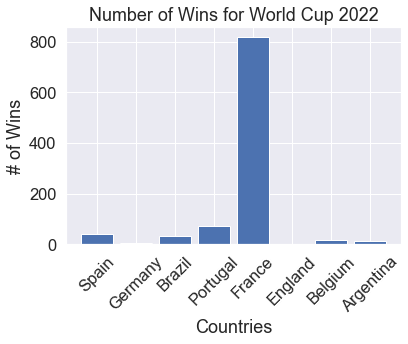

In [57]:
#plot the number of predicted world cup wins 
set_winners = set(winners)
win_country = []
win_count = []
for country in set_winners:
    win_country.append(country)
    win_count.append(winners.count(country))
print(win_country)
print(win_count)

plt.bar(win_country, win_count)
plt.title("Number of Wins for World Cup 2022")
plt.xlabel("Countries")
plt.ylabel("# of Wins")
plt.xticks(rotation=45)
plt.show()